# 03 — Analyse

**Source :** [Online Retail sur Kaggle](https://www.kaggle.com/datasets/carrie1/ecommerce-data), données d'origine UCI, licence CC BY 4.0

**Questions traitées :**

**Q1**. Quels pays, hors Royaume-Uni, rapportent le plus de chiffre d'affaires ?

**Q4**. Quels produits rapportent le plus de chiffre d'affaires ?

**Objectif de ce notebook :** Répondre aux questions 1 et 4 à partir du fichier propre

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
vente = pd.read_csv("../data/processed/online_retail_propre.csv", parse_dates=["InvoiceDate"], dtype={"InvoiceNo": "str", "StockCode": "str", "CustomerID": "str"}, encoding="latin-1")
vente.shape

(524876, 9)

**NOMBRE DE PAYS**

In [3]:
vente["Country"].nunique()

38

**NOMBRE DE FACTURE**

In [4]:
vente["InvoiceNo"].nunique() 

19958

**NOMBRE DE CLIENT IDENTIFIE**

In [5]:
vente[vente["CustomerID"] !="Inconnu"]["CustomerID"].nunique()

4337

**CA TOTAL**

In [6]:
vente["CA"].sum()

np.float64(10396457.6)

Quels pays, hors Royaume-Uni, rapportent le plus de chiffre d'affaires ?


In [7]:
ca_par_pays = (
               vente[vente["Country"] != "United Kingdom"]
               .groupby("Country")["CA"]
               .sum()
               .sort_values(ascending=False)
               .head(10)
)
print(ca_par_pays)

Country
Netherlands    285446.34
EIRE           283140.52
Germany        228678.40
France         209625.37
Australia      138453.81
Spain           61558.56
Switzerland     57067.60
Belgium         41196.34
Sweden          38367.83
Japan           37416.37
Name: CA, dtype: float64


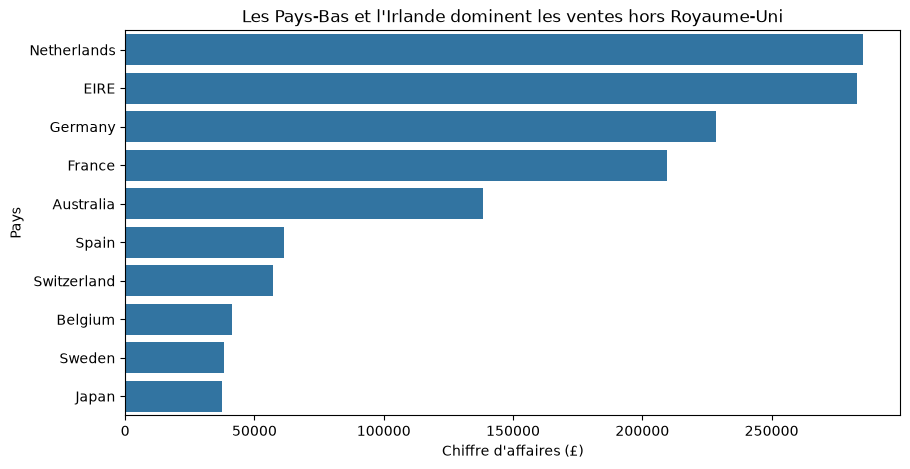

In [8]:
graph_pays = ca_par_pays.reset_index()                    

fig, ax = plt.subplots(figsize=(10, 5))                  
sns.barplot(data=graph_pays, x="CA", y="Country", ax=ax)  
ax.set_title("Les Pays-Bas et l'Irlande dominent les ventes hors Royaume-Uni") 
ax.set_xlabel("Chiffre d'affaires (£)")                   
ax.set_ylabel("Pays")                                     
fig.savefig("../figures/ca_par_pays.png", dpi=150, bbox_inches="tight")   
plt.show()                                  

Le pays hors Royaume-Uni rapportant le plus d'argent est les Pays-Bas

**Quels produits rapportent le plus de chiffre d’affaires ?**

Codes non-produits : retirés car ce sont des frais (port, banque, Amazon…), pas des produits

In [9]:
codes_non_produits = ["POST", "DOT", "M", "AMAZONFEE", "B", "BANK CHARGES", "S"]
print(len(vente))
produits = vente[~vente["StockCode"].isin(codes_non_produits)]
print(len(produits))

524876
522710


In [10]:
top_produits = (
    produits
    .groupby("Description")["CA"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
print(top_produits)

Description
REGENCY CAKESTAND 3 TIER              174156.54
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
RABBIT NIGHT LIGHT                     66870.03
PAPER CHAIN KIT 50'S CHRISTMAS         64875.59
ASSORTED COLOUR BIRD ORNAMENT          58927.62
CHILLI LIGHTS                          54096.36
SPOTTY BUNTING                         42513.48
JUMBO BAG PINK POLKADOT                42401.01
Name: CA, dtype: float64


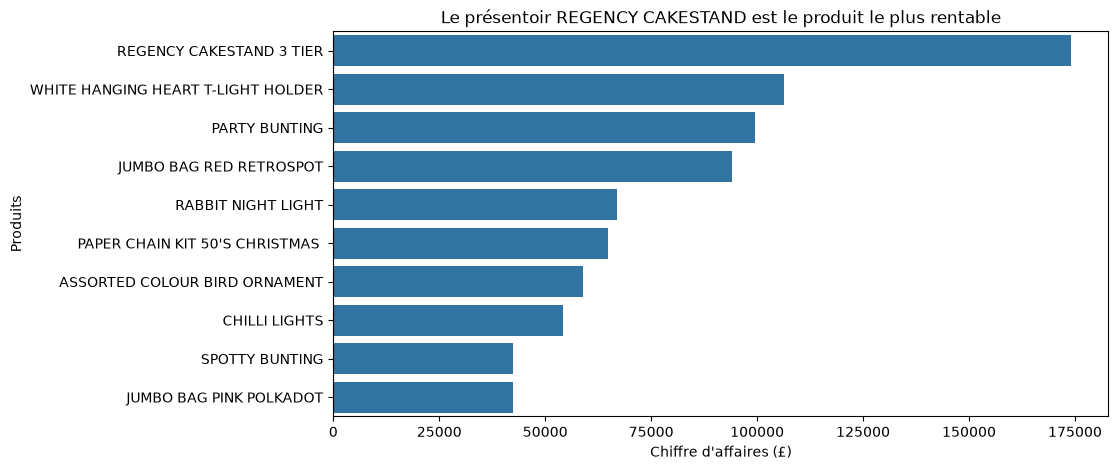

In [11]:
graph_produits = top_produits.reset_index()                    

fig, ax = plt.subplots(figsize=(10, 5))                  
sns.barplot(data=graph_produits, x="CA", y="Description", ax=ax)  
ax.set_title("Le présentoir REGENCY CAKESTAND est le produit le plus rentable") 
ax.set_xlabel("Chiffre d'affaires (£)")                   
ax.set_ylabel("Produits")                                     
fig.savefig("../figures/top_produits.png", dpi=150, bbox_inches="tight")   
plt.show()                                  

REGENCY CAKESTAND est de loin le produit le plus rentable